# 🐾 AdotaIA: previsão de adoção de animais em abrigos

**Projeto Integrador Extensionista: Inteligência Artificial e Aprendizado de Máquina**

- **Instituição beneficiada:** ONG Patinhas do Bem (nome fictício: ainda não há uma ONG parceira definida)
- **Entrega:** etapa prática (notebook + protótipo), 20/11/2026

> ⚠️ **Atenção:** todos os dados usados neste notebook são **fictícios (sintéticos)**, gerados pelo próprio
> código. Eles servem apenas para construir e testar o protótipo. Os resultados **não** representam o
> desempenho real do modelo em um abrigo.

Este notebook roda do início ao fim no Google Colab, sem depender de arquivos externos.

In [1]:
# Instala o Gradio (as demais bibliotecas já vêm instaladas no Colab)
%pip install -q gradio

In [2]:
# Importação das bibliotecas usadas no projeto
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

# Semente fixa: garante que os dados e os resultados sejam sempre os mesmos (reprodutibilidade)
SEED = 42

sns.set_theme(style="whitegrid")
print("Bibliotecas carregadas!")

Bibliotecas carregadas!


## Etapa 1: Retomada do planejamento

### O problema
Abrigos e ONGs de proteção animal têm **recursos limitados para divulgação** (tempo dos voluntários,
posts nas redes sociais, fotos, eventos de adoção). Alguns animais, como adultos, idosos, de porte
grande, de pelagem escura ou tímidos, costumam ficar muito tempo sem ser adotados. Hoje a ONG não tem
uma forma de identificar **com antecedência** quais animais precisam de mais atenção.

### Objetivo
Construir um sistema que, a partir das características de um animal, **estime a chance de ele ser
adotado em até 30 dias** e **sugira ações práticas** (priorizar a divulgação, tirar fotos melhores,
castrar, vacinar etc.).

### Como a IA é usada
- Tipo de tarefa: **classificação binária supervisionada**.
- Entrada (X): características do animal (espécie, idade, porte, temperamento, saúde, divulgação...).
- Saída (y): `adotado_30_dias` → **1** = adotado em até 30 dias, **0** = não adotado nesse prazo.
- O modelo devolve uma **probabilidade**, que o sistema transforma em uma classificação
  (alta / média / baixa chance) e em recomendações.

### Público beneficiado
Voluntários e coordenadores da ONG, que poderão decidir melhor **onde investir o esforço de divulgação**.

## Etapa 2: Organização dos dados

### 2.1 Por que dados sintéticos?
Ainda não recebemos os dados reais da ONG. Para não travar o desenvolvimento, criamos uma **base
sintética** com cerca de 800 animais fictícios. A semente fixa (`SEED = 42`) faz com que a base gerada
seja sempre igual.

O alvo **não é aleatório**: ele segue uma regra probabilística (função logística) baseada no que a
literatura e os voluntários de abrigos costumam relatar:

- **aumentam a chance:** filhotes, animais castrados/vacinados/vermifugados, dóceis, com boas fotos e
  com mais divulgações;
- **diminuem a chance:** idosos, porte grande, pelagem preta, com deficiência, tímidos e que já estão
  há muito tempo no abrigo.

Além disso, adicionamos um **ruído aleatório**, porque na vida real nem tudo é explicado pelas
características do animal.

In [3]:
# Gerador de números aleatórios com semente fixa
rng = np.random.default_rng(SEED)
N = 800  # quantidade de animais fictícios

# --- Colunas de entrada (X) ---
especie = rng.choice(["cão", "gato"], size=N, p=[0.6, 0.4])

# Idade em meses (1 a 180). Usamos uma distribuição exponencial porque abrigos
# recebem mais filhotes e jovens do que idosos.
idade_meses = np.clip(rng.exponential(scale=40, size=N).astype(int) + 1, 1, 180)

# Porte: gatos são sempre pequenos ou médios
porte = np.where(
    especie == "cão",
    rng.choice(["pequeno", "médio", "grande"], size=N, p=[0.35, 0.35, 0.30]),
    rng.choice(["pequeno", "médio"], size=N, p=[0.6, 0.4]),
)

sexo = rng.choice(["macho", "fêmea"], size=N)
cor_pelagem = rng.choice(["preta", "clara", "mista"], size=N, p=[0.30, 0.35, 0.35])
vacinado = rng.choice(["sim", "não"], size=N, p=[0.70, 0.30])
castrado = rng.choice(["sim", "não"], size=N, p=[0.55, 0.45])
vermifugado = rng.choice(["sim", "não"], size=N, p=[0.75, 0.25])
possui_deficiencia = rng.choice(["sim", "não"], size=N, p=[0.08, 0.92])
temperamento = rng.choice(["dócil", "tímido", "agitado"], size=N, p=[0.5, 0.3, 0.2])
tempo_abrigo_dias = np.clip(rng.exponential(scale=60, size=N).astype(int) + 1, 1, 365)
qtd_divulgacoes = rng.poisson(lam=3, size=N)        # número de posts nas redes sociais
foto_boa_qualidade = rng.choice(["sim", "não"], size=N, p=[0.5, 0.5])

dados = pd.DataFrame({
    "especie": especie,
    "idade_meses": idade_meses,
    "porte": porte,
    "sexo": sexo,
    "cor_pelagem": cor_pelagem,
    "vacinado": vacinado,
    "castrado": castrado,
    "vermifugado": vermifugado,
    "possui_deficiencia": possui_deficiencia,
    "temperamento": temperamento,
    "tempo_abrigo_dias": tempo_abrigo_dias,
    "qtd_divulgacoes": qtd_divulgacoes,
    "foto_boa_qualidade": foto_boa_qualidade,
})
dados.head()

,especie,idade_meses,porte,sexo,cor_pelagem,vacinado,castrado,vermifugado,possui_deficiencia,temperamento,tempo_abrigo_dias,qtd_divulgacoes,foto_boa_qualidade
0,gato,97,médio,macho,preta,sim,não,não,não,dócil,29,2,sim
1,cão,17,médio,macho,mista,não,sim,não,sim,dócil,34,4,sim
2,gato,120,médio,macho,preta,sim,sim,sim,não,agitado,33,3,não
3,gato,46,pequeno,fêmea,mista,sim,sim,sim,não,tímido,94,4,não
4,cão,2,grande,macho,clara,sim,não,sim,não,dócil,30,1,sim


### 2.2 Regra de geração do alvo `adotado_30_dias`
Calculamos uma **pontuação** para cada animal (somando pesos positivos e negativos), adicionamos ruído e
passamos o resultado por uma **função logística (sigmoide)**, que transforma a pontuação em uma
probabilidade entre 0 e 1. Depois "sorteamos" se o animal foi adotado com essa probabilidade.

In [4]:
def sigmoide(z):
    """Transforma qualquer número real em uma probabilidade entre 0 e 1."""
    return 1 / (1 + np.exp(-z))

# Pontuação de cada animal (valores escolhidos pelo autor para refletir padrões plausíveis)
pontuacao = (
    - 0.80                                                 # intercepto (ajusta o equilíbrio das classes)
    + 1.20 * (dados["idade_meses"] <= 12)                  # filhote: + chance
    - 1.00 * (dados["idade_meses"] > 96)                   # idoso (mais de 8 anos): - chance
    - 0.80 * (dados["porte"] == "grande")                  # porte grande: - chance
    + 0.30 * (dados["porte"] == "pequeno")                 # porte pequeno: + chance
    - 0.60 * (dados["cor_pelagem"] == "preta")             # pelagem preta: - chance
    + 0.50 * (dados["vacinado"] == "sim")
    + 0.60 * (dados["castrado"] == "sim")
    + 0.20 * (dados["vermifugado"] == "sim")
    - 1.20 * (dados["possui_deficiencia"] == "sim")
    + 0.50 * (dados["temperamento"] == "dócil")
    - 0.70 * (dados["temperamento"] == "tímido")
    - 0.20 * (dados["temperamento"] == "agitado")
    + 0.80 * (dados["foto_boa_qualidade"] == "sim")
    + 0.25 * (dados["qtd_divulgacoes"] - 3)                # cada post a mais ajuda um pouco
    - 0.005 * (dados["tempo_abrigo_dias"] - 60)            # muito tempo no abrigo: - chance
)

ruido = rng.normal(loc=0, scale=0.5, size=N)               # fatores que não estão nos dados
probabilidade = sigmoide(pontuacao + ruido)

# Sorteio do resultado: 1 = adotado em até 30 dias, 0 = não adotado
dados["adotado_30_dias"] = (rng.random(N) < probabilidade).astype(int)

print(f"Total de registros: {len(dados)}")
print(f"Percentual de adotados: {dados['adotado_30_dias'].mean():.1%}")

Total de registros: 800
Percentual de adotados: 54.1%


In [5]:
# Salva a base sintética em CSV
os.makedirs("dados", exist_ok=True)
dados.to_csv("dados/animais_sinteticos.csv", index=False, encoding="utf-8")
print("Base salva em dados/animais_sinteticos.csv")

# Conferências básicas de qualidade dos dados
print("\nValores ausentes por coluna:", dados.isna().sum().sum())
print("Gatos de porte grande (deve ser 0):", ((dados["especie"] == "gato") & (dados["porte"] == "grande")).sum())
dados.describe()

Base salva em dados/animais_sinteticos.csv

Valores ausentes por coluna: 0
Gatos de porte grande (deve ser 0): 0


,idade_meses,tempo_abrigo_dias,qtd_divulgacoes,adotado_30_dias
count,800.000000,800.000000,800.000000,800.000000
mean,40.195000,60.045000,3.003750,0.541250
std,37.154475,60.964119,1.759291,0.498607
min,1.000000,1.000000,0.000000,0.000000
25%,13.000000,17.000000,2.000000,0.000000
50%,29.000000,39.500000,3.000000,1.000000
75%,56.000000,81.000000,4.000000,1.000000
max,180.000000,365.000000,10.000000,1.000000


### 2.3 Análise exploratória
Antes de treinar o modelo, olhamos rapidamente para os dados para conferir se os padrões fazem sentido.

adotado_30_dias
Adotado        433
Não adotado    367
Name: count, dtype: int64


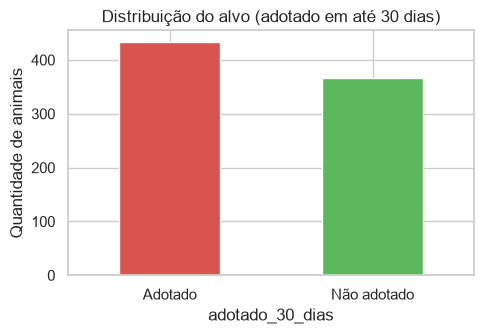

In [6]:
# Distribuição do alvo: as classes devem estar razoavelmente equilibradas
contagem = dados["adotado_30_dias"].value_counts().rename({0: "Não adotado", 1: "Adotado"})
print(contagem)

ax = contagem.plot(kind="bar", color=["#d9534f", "#5cb85c"], rot=0, figsize=(5, 3.5))
ax.set_title("Distribuição do alvo (adotado em até 30 dias)")
ax.set_ylabel("Quantidade de animais")
plt.tight_layout()
plt.show()

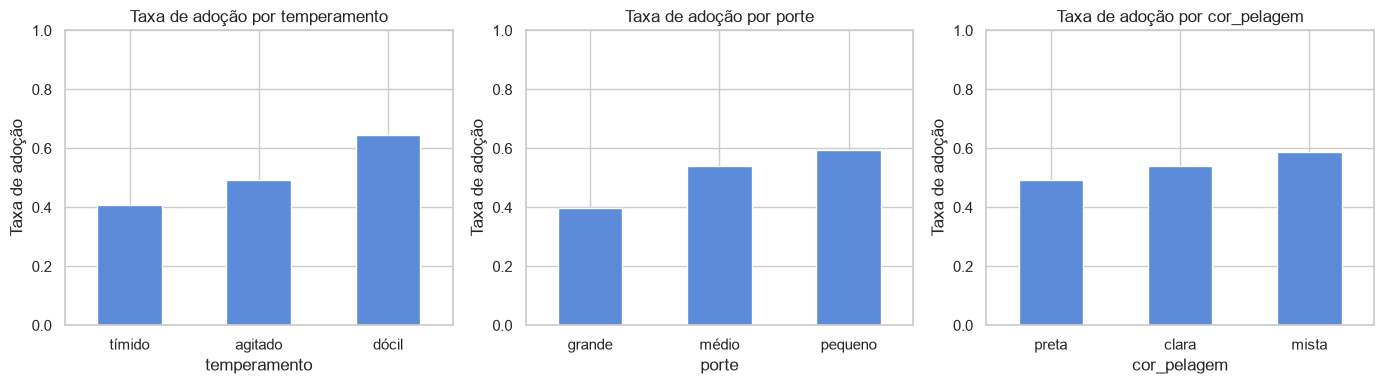

In [7]:
# Taxa de adoção por algumas características categóricas
fig, eixos = plt.subplots(1, 3, figsize=(14, 4))
for eixo, coluna in zip(eixos, ["temperamento", "porte", "cor_pelagem"]):
    taxa = dados.groupby(coluna)["adotado_30_dias"].mean().sort_values()
    taxa.plot(kind="bar", ax=eixo, color="#5b8bd9", rot=0)
    eixo.set_title(f"Taxa de adoção por {coluna}")
    eixo.set_ylabel("Taxa de adoção")
    eixo.set_ylim(0, 1)
plt.tight_layout()
plt.show()

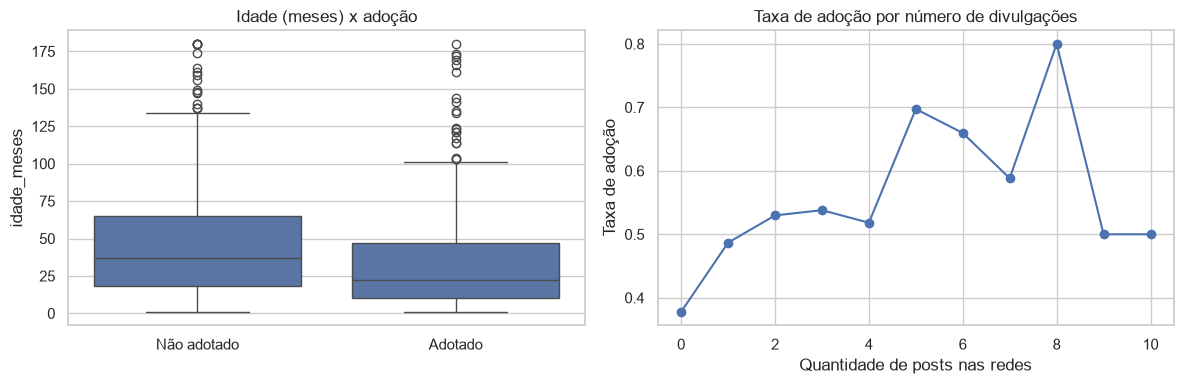

In [8]:
# Idade e número de divulgações x adoção
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=dados, x="adotado_30_dias", y="idade_meses", ax=eixos[0])
eixos[0].set_title("Idade (meses) x adoção")
eixos[0].set_xticks([0, 1], ["Não adotado", "Adotado"])
eixos[0].set_xlabel("")

dados.groupby("qtd_divulgacoes")["adotado_30_dias"].mean().plot(ax=eixos[1], marker="o")
eixos[1].set_title("Taxa de adoção por número de divulgações")
eixos[1].set_xlabel("Quantidade de posts nas redes")
eixos[1].set_ylabel("Taxa de adoção")
plt.tight_layout()
plt.show()

**Leitura dos gráficos:** animais dóceis, de porte pequeno e de pelagem clara/mista são adotados com mais
frequência; os adotados tendem a ser mais jovens; e quanto mais divulgações, maior a taxa de adoção.
Isso é esperado, porque foi exatamente a regra que usamos para gerar os dados.

### 2.4 Como obteremos os dados reais
1. **Fontes:** planilhas de cadastro de animais da ONG (ficha de entrada: espécie, idade estimada,
   porte, saúde, temperamento), histórico de adoções (data de entrada e data de adoção, para calcular
   o alvo `adotado_30_dias`) e registro dos posts feitos nas redes sociais.
2. **Autorização:** solicitar à coordenação da ONG uma autorização formal (termo de uso de dados)
   para usar as informações no projeto acadêmico.
3. **LGPD:** os dados dos **animais** não são dados pessoais, mas as planilhas de adoção costumam ter
   dados dos **adotantes** (nome, CPF, telefone, endereço). Esses campos **não serão coletados**: pediremos
   que a ONG exporte apenas as colunas do animal e as datas, ou faremos a anonimização antes de qualquer
   uso. Os arquivos ficarão em local com acesso restrito ao autor do projeto e serão apagados ao fim do projeto.
4. **Limpeza:** padronizar categorias escritas de formas diferentes, tratar idades estimadas e
   campos em branco, e conferir com os voluntários os casos estranhos.

## Etapa 3: Implementação do modelo

### 3.1 Separação entre treino e teste
Separamos **80% dos dados para treino** e **20% para teste**. A divisão é **estratificada**, ou seja,
mantém a mesma proporção de adotados e não adotados nos dois conjuntos.

In [9]:
COLUNAS_CATEGORICAS = ["especie", "porte", "sexo", "cor_pelagem", "vacinado", "castrado",
                       "vermifugado", "possui_deficiencia", "temperamento", "foto_boa_qualidade"]
COLUNAS_NUMERICAS = ["idade_meses", "tempo_abrigo_dias", "qtd_divulgacoes"]

X = dados[COLUNAS_CATEGORICAS + COLUNAS_NUMERICAS]
y = dados["adotado_30_dias"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print(f"Treino: {len(X_treino)} animais | Teste: {len(X_teste)} animais")

Treino: 640 animais | Teste: 160 animais


### 3.2 Pré-processamento com Pipeline
Os algoritmos trabalham com números, então:
- **OneHotEncoder** transforma cada categoria em colunas 0/1 (ex.: `porte_grande`, `porte_médio`...);
- **StandardScaler** coloca as colunas numéricas na mesma escala (média 0, desvio 1).

Tudo fica dentro de um **Pipeline**: assim o mesmo tratamento é aplicado no treino, no teste e no
protótipo, sem risco de esquecer algum passo.

In [10]:
def criar_preprocessador():
    """Cria o ColumnTransformer que trata colunas categóricas e numéricas."""
    return ColumnTransformer([
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), COLUNAS_CATEGORICAS),
        ("numericas", StandardScaler(), COLUNAS_NUMERICAS),
    ])

# Os três algoritmos que vamos comparar
modelos = {
    "Árvore de Decisão": DecisionTreeClassifier(max_depth=5, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED),
    "Regressão Logística": LogisticRegression(max_iter=1000),
}

pipelines = {}
for nome, algoritmo in modelos.items():
    pipe = Pipeline([
        ("preprocessamento", criar_preprocessador()),
        ("modelo", algoritmo),
    ])
    pipe.fit(X_treino, y_treino)   # treinamento
    pipelines[nome] = pipe
    print(f"{nome}: treinado")

Árvore de Decisão: treinado


Random Forest: treinado
Regressão Logística: treinado


## Etapa 4: Protótipo do sistema

O protótipo usa o **melhor modelo** (escolhido na Etapa 5, logo abaixo, mas já definido aqui) e
uma interface feita com **Gradio**. O voluntário preenche os dados do animal e recebe:

1. a **probabilidade** de adoção em até 30 dias;
2. uma **classificação**: alta (≥ 60%), média (40% a 60%) ou baixa (< 40%) chance;
3. até **3 recomendações práticas**, geradas por regras simples a partir dos dados digitados.

> Para manter a ordem das etapas da atividade, primeiro avaliamos os modelos (Etapa 5) e depois
> abrimos a interface no final do notebook. As funções do protótipo são definidas aqui.

In [11]:
def classificar_chance(prob):
    """Converte a probabilidade em uma faixa fácil de entender."""
    if prob >= 0.6:
        return "Alta chance"
    elif prob >= 0.4:
        return "Média chance"
    return "Baixa chance"


def gerar_recomendacoes(animal, limite=3):
    """Gera recomendações por regras simples, a partir dos dados digitados (dicionário)."""
    dicas = []
    if animal["castrado"] == "não":
        dicas.append("Castrar o animal: animais castrados costumam ser adotados mais rápido.")
    if animal["foto_boa_qualidade"] == "não":
        dicas.append("Fazer fotos novas, com boa luz e mostrando o rosto e a personalidade do animal.")
    if animal["qtd_divulgacoes"] < 3:
        dicas.append("Priorizar este animal nas redes sociais (ele teve poucas divulgações).")
    if animal["vacinado"] == "não":
        dicas.append("Atualizar a vacinação e destacar isso na divulgação.")
    if animal["temperamento"] == "tímido":
        dicas.append("Investir em socialização e descrever o jeito do animal no post (ex.: 'carinhoso depois que confia').")
    if animal["possui_deficiencia"] == "sim":
        dicas.append("Contar a história do animal e mostrar que a deficiência não impede uma vida feliz.")
    if animal["idade_meses"] > 96 or animal["porte"] == "grande" or animal["cor_pelagem"] == "preta":
        dicas.append("Incluir em campanhas específicas (ex.: 'Adote um idoso', 'Adote um pretinho', 'Adote um grandão').")
    if animal["vermifugado"] == "não":
        dicas.append("Vermifugar o animal antes das feiras de adoção.")
    if animal["tempo_abrigo_dias"] > 90:
        dicas.append("Dar destaque especial: ele já está há mais de 3 meses esperando um lar.")
    if not dicas:
        dicas.append("O perfil é favorável: manter a divulgação atual e levar às feiras de adoção.")
    return dicas[:limite]


def prever_adocao(modelo, animal):
    """Recebe um dicionário com os dados do animal e devolve (probabilidade, faixa, recomendações)."""
    entrada = pd.DataFrame([animal])
    prob = modelo.predict_proba(entrada)[0, 1]   # probabilidade da classe 1 (adotado)
    return prob, classificar_chance(prob), gerar_recomendacoes(animal)

## Etapa 5: Testes e avaliação inicial

### 5.1 Métricas no conjunto de teste
Usamos quatro métricas:
- **Acurácia:** % de acertos no total.
- **Precisão:** dos animais que o modelo disse que seriam adotados, quantos realmente foram.
- **Recall (sensibilidade):** dos animais de uma classe, quantos o modelo encontrou.
- **F1:** média harmônica entre precisão e recall.

**Por que o recall da classe "não adotado" é importante?** O objetivo da ONG é encontrar os animais
que **precisam de ajuda**. Se o modelo diz que um animal será adotado, mas ele não é (um falso
"adotado"), esse animal fica sem a atenção extra de que precisava. Por isso olhamos com cuidado o
**recall da classe 0**: ele mede quantos dos animais que realmente não foram adotados o modelo
conseguiu identificar.

In [12]:
resultados = []
for nome, pipe in pipelines.items():
    previsto = pipe.predict(X_teste)
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, previsto),
        "Precisão": precision_score(y_teste, previsto),
        "Recall": recall_score(y_teste, previsto),
        "F1": f1_score(y_teste, previsto),
        "Recall 'não adotado'": recall_score(y_teste, previsto, pos_label=0),
    })

tabela = pd.DataFrame(resultados).set_index("Modelo").round(3)
tabela

,Acurácia,Precisão,Recall,F1,Recall 'não adotado'
Modelo,,,,,
Árvore de Decisão,0.588,0.596,0.747,0.663,0.397
Random Forest,0.681,0.676,0.793,0.730,0.548
Regressão Logística,0.744,0.730,0.839,0.781,0.630


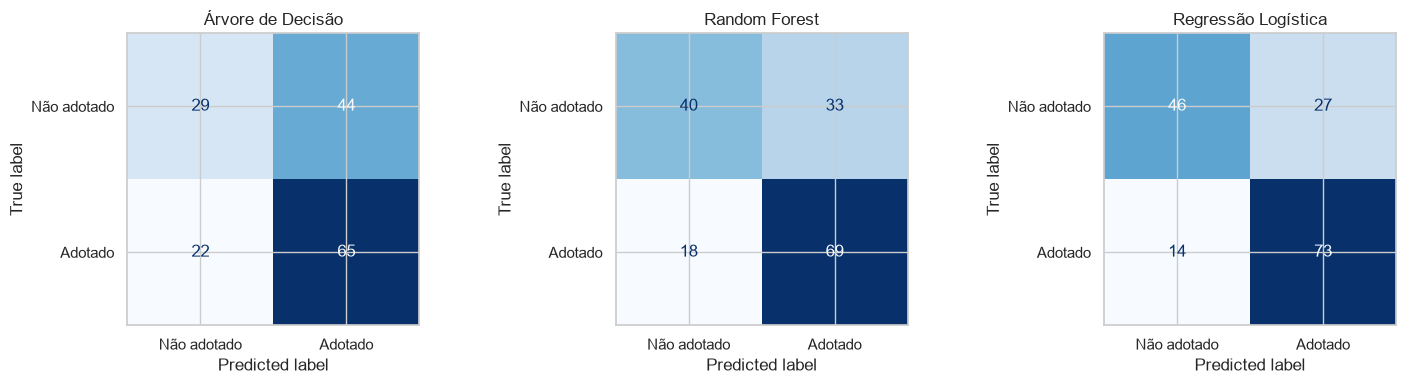

In [13]:
# Matriz de confusão de cada modelo
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
for eixo, (nome, pipe) in zip(eixos, pipelines.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_teste, y_teste, ax=eixo, colorbar=False,
        display_labels=["Não adotado", "Adotado"], cmap="Blues",
    )
    eixo.set_title(nome)
plt.tight_layout()
plt.show()

### 5.2 Escolha do melhor modelo
Critério: **maior F1 médio entre as duas classes** (`f1_score(..., average="macro")`), porque queremos um
modelo equilibrado, que acerte tanto os adotados quanto os não adotados.

In [14]:
f1_macro = {nome: f1_score(y_teste, pipe.predict(X_teste), average="macro")
            for nome, pipe in pipelines.items()}
for nome, valor in f1_macro.items():
    print(f"{nome:22s} F1 macro = {valor:.3f}")

nome_melhor = max(f1_macro, key=f1_macro.get)
melhor_modelo = pipelines[nome_melhor]
print(f"\nMelhor modelo: {nome_melhor}")

print("\nRelatório completo do melhor modelo:")
print(classification_report(y_teste, melhor_modelo.predict(X_teste),
                            target_names=["Não adotado", "Adotado"]))

Árvore de Decisão      F1 macro = 0.566
Random Forest          F1 macro = 0.670
Regressão Logística    F1 macro = 0.736

Melhor modelo: Regressão Logística

Relatório completo do melhor modelo:
              precision    recall  f1-score   support

 Não adotado       0.77      0.63      0.69        73
     Adotado       0.73      0.84      0.78        87

    accuracy                           0.74       160
   macro avg       0.75      0.73      0.74       160
weighted avg       0.75      0.74      0.74       160



### 5.3 Importância das variáveis
Mostramos quais variáveis mais pesam na decisão do melhor modelo. Para a Regressão Logística usamos os
**coeficientes** (positivo = aumenta a chance de adoção; negativo = diminui). Para os modelos de árvore,
usamos a `feature_importances_`.

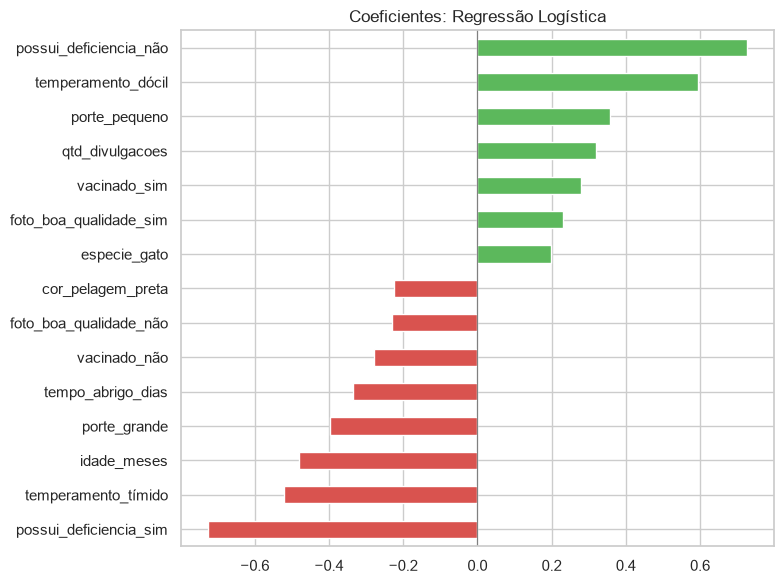

In [15]:
nomes_colunas = melhor_modelo.named_steps["preprocessamento"].get_feature_names_out()
nomes_colunas = [n.split("__")[1] for n in nomes_colunas]   # tira o prefixo "categoricas__"/"numericas__"
algoritmo = melhor_modelo.named_steps["modelo"]

if hasattr(algoritmo, "coef_"):
    importancia = pd.Series(algoritmo.coef_[0], index=nomes_colunas)
    titulo = f"Coeficientes: {nome_melhor}"
else:
    importancia = pd.Series(algoritmo.feature_importances_, index=nomes_colunas)
    titulo = f"Importância das variáveis: {nome_melhor}"

# Mostra as 15 variáveis com maior peso (em valor absoluto)
top = importancia.reindex(importancia.abs().sort_values(ascending=False).index).head(15)
top = top.sort_values()
cores = ["#5cb85c" if v > 0 else "#d9534f" for v in top]   # verde = aumenta, vermelho = diminui
top.plot(kind="barh", figsize=(8, 6), color=cores)
plt.title(titulo)
plt.axvline(0, color="gray", linewidth=0.8)
plt.tight_layout()
plt.show()

### 5.4 Salvando o modelo
O pipeline completo (pré-processamento + modelo) é salvo com o **joblib**. O `app.py` carrega esse
arquivo para rodar o protótipo fora do Colab.

In [16]:
os.makedirs("modelo", exist_ok=True)
joblib.dump(melhor_modelo, "modelo/modelo_adocao.joblib")
print(f"Modelo '{nome_melhor}' salvo em modelo/modelo_adocao.joblib")

Modelo 'Regressão Logística' salvo em modelo/modelo_adocao.joblib


### 5.5 Testes do protótipo com casos de exemplo
Testamos o sistema com animais "extremos" para verificar se as respostas são **coerentes** com o
esperado. Os `assert` fazem o notebook dar erro caso algum teste falhe.

In [17]:
# Caso 1: filhote dócil, saudável, com boa foto e bastante divulgação (deveria ter ALTA chance)
filhote = {
    "especie": "cão", "idade_meses": 4, "porte": "pequeno", "sexo": "fêmea", "cor_pelagem": "clara",
    "vacinado": "sim", "castrado": "sim", "vermifugado": "sim", "possui_deficiencia": "não",
    "temperamento": "dócil", "tempo_abrigo_dias": 10, "qtd_divulgacoes": 6, "foto_boa_qualidade": "sim",
}

# Caso 2: cão idoso, grande, preto, tímido, sem castração e pouco divulgado (deveria ter BAIXA chance)
idoso = {
    "especie": "cão", "idade_meses": 130, "porte": "grande", "sexo": "macho", "cor_pelagem": "preta",
    "vacinado": "não", "castrado": "não", "vermifugado": "não", "possui_deficiencia": "sim",
    "temperamento": "tímido", "tempo_abrigo_dias": 200, "qtd_divulgacoes": 0, "foto_boa_qualidade": "não",
}

for nome_caso, animal in [("Filhote", filhote), ("Idoso", idoso)]:
    prob, faixa, dicas = prever_adocao(melhor_modelo, animal)
    print(f"{nome_caso}: {prob:.1%} -> {faixa}")
    for d in dicas:
        print("   •", d)

# Testes automáticos de coerência
prob_filhote = prever_adocao(melhor_modelo, filhote)[0]
prob_idoso = prever_adocao(melhor_modelo, idoso)[0]
assert prob_filhote > prob_idoso, "O filhote deveria ter mais chance que o idoso"
assert classificar_chance(prob_filhote) == "Alta chance"
assert classificar_chance(prob_idoso) == "Baixa chance"
assert len(gerar_recomendacoes(idoso)) <= 3
print("\n✅ Todos os testes de coerência passaram!")

Filhote: 95.2% -> Alta chance
   • O perfil é favorável: manter a divulgação atual e levar às feiras de adoção.
Idoso: 0.2% -> Baixa chance
   • Castrar o animal: animais castrados costumam ser adotados mais rápido.
   • Fazer fotos novas, com boa luz e mostrando o rosto e a personalidade do animal.
   • Priorizar este animal nas redes sociais (ele teve poucas divulgações).

✅ Todos os testes de coerência passaram!


In [18]:
# Teste de sensibilidade: o que acontece com o idoso se a ONG agir sobre o que é possível mudar?
idoso_com_acoes = dict(idoso, castrado="sim", vacinado="sim", vermifugado="sim",
                       foto_boa_qualidade="sim", qtd_divulgacoes=6)
antes = prever_adocao(melhor_modelo, idoso)[0]
depois = prever_adocao(melhor_modelo, idoso_com_acoes)[0]
print(f"Chance antes das ações:  {antes:.1%}")
print(f"Chance depois das ações: {depois:.1%}")
assert depois > antes

Chance antes das ações:  0.2%
Chance depois das ações: 2.6%


### 5.6 Discussão dos resultados

**Algoritmo escolhido e por quê.** Comparamos Árvore de Decisão, Random Forest e Regressão Logística.
O melhor F1 macro ficou com o modelo indicado na célula 5.2 (**Regressão Logística**, F1 macro = 0,736, contra 0,670 da Random Forest e 0,566 da Árvore de Decisão). Isso faz sentido: como a base
sintética foi gerada por uma **função logística**, a Regressão Logística tem exatamente a "forma" da
regra que produziu os dados. Ela também tem a vantagem de ser **fácil de explicar** para a ONG, já que
cada coeficiente mostra se a característica aumenta ou diminui a chance.

**Como foi treinado.** Pipeline com OneHotEncoder + StandardScaler, divisão 80/20 estratificada com
`random_state=42`, parâmetros simples (árvore com profundidade 5, floresta com 200 árvores, regressão com
`max_iter=1000`).

**Resultado obtido.** No conjunto de teste (160 animais), os três modelos ficaram com acurácia entre
59% (Árvore de Decisão) e 74% (Regressão Logística). O melhor modelo teve acurácia de 74,4%, F1 de 0,78 (classe "adotado"; 0,74 na média das duas classes) e recall da classe "não adotado"
de 63%: de cada 10 animais que de fato não foram adotados, o modelo identificou cerca de 6.

**Os resultados são coerentes?** Sim, dentro do esperado:
- as variáveis mais importantes (idade, deficiência, foto, temperamento, castração, divulgações, porte,
  pelagem) são as mesmas que usamos na regra de geração;
- o filhote dócil recebeu alta chance e o idoso tímido recebeu baixa chance;
- ações que a ONG pode tomar (castrar, vacinar, fotografar, divulgar) aumentam a probabilidade prevista.

Um acerto perto de 75% (e não 100%) também é coerente, porque colocamos **ruído** e um sorteio na
geração do alvo, imitando a incerteza da vida real.

**Limitações.**
- **Dados sintéticos não comprovam desempenho real.** O modelo aprendeu a regra que nós mesmos
  inventamos; com dados da ONG os resultados podem ser bem diferentes.
- **Viés da regra de geração:** os pesos refletem a opinião do autor e da literatura, não medições.
- **Correlações ao acaso:** a variável `especie_gato` aparece com peso positivo no gráfico de coeficientes,
  mesmo sem fazer parte da regra de geração. Com poucos dados, o modelo pode "aprender" padrões que
  são só coincidência da amostra.
- **Poucos dados:** 800 registros (e só 160 no teste) dão métricas com bastante variação.
- Faltam variáveis que provavelmente importam na prática (raça, estação do ano, eventos de adoção,
  convivência com outros animais e crianças).
- As recomendações são **regras fixas**, não aprendidas pelo modelo.

**Próximos passos.**
1. Coletar e anonimizar os dados reais da ONG e retreinar o modelo.
2. Usar validação cruzada e ajuste de hiperparâmetros (GridSearchCV).
3. Ajustar o limiar de decisão para aumentar o recall dos "não adotados".
4. Validar as recomendações com os voluntários.
5. Publicar o protótipo online (Hugging Face Spaces).

## Protótipo: interface Gradio
Execute a célula abaixo. Ao clicar em **Prever chance**, o modelo (Python) calcula o resultado e um
trecho de **JavaScript** abre uma janela por cima da página com a probabilidade, a faixa de chance e as
recomendações. O resultado também fica escrito abaixo do botão.

**No Colab** aparece um link público (`share=True`) que pode ser aberto no celular dos voluntários.
Fora do Colab, a interface abre apenas no endereço local.

In [19]:
import gradio as gr

def interface_prever(especie, idade_anos, idade_meses, porte, sexo, cor_pelagem, vacinado, castrado,
                     vermifugado, possui_deficiencia, temperamento, tempo_abrigo_dias,
                     qtd_divulgacoes, foto_boa_qualidade):
    """Função chamada quando o usuário clica em 'Prever chance'.

    Devolve dois valores:
      1. um texto em Markdown, mostrado na própria página;
      2. um dicionário com os resultados, que o JavaScript usa para montar a janela.
    """
    # A idade é digitada em anos + meses e convertida para meses (o modelo usa meses)
    total_meses = int(idade_anos or 0) * 12 + int(idade_meses or 0)
    if total_meses < 1 or total_meses > 180:
        aviso = "A idade deve ficar entre 1 mês e 15 anos."
        return f"⚠️ {aviso}", {"erro": aviso}

    # Gatos no cadastro são sempre pequenos ou médios
    if especie == "gato" and porte == "grande":
        aviso = "Para gatos, escolha porte pequeno ou médio."
        return f"⚠️ {aviso}", {"erro": aviso}

    animal = {
        "especie": especie, "idade_meses": total_meses, "porte": porte, "sexo": sexo,
        "cor_pelagem": cor_pelagem, "vacinado": vacinado, "castrado": castrado,
        "vermifugado": vermifugado, "possui_deficiencia": possui_deficiencia,
        "temperamento": temperamento, "tempo_abrigo_dias": int(tempo_abrigo_dias or 0),
        "qtd_divulgacoes": int(qtd_divulgacoes or 0), "foto_boa_qualidade": foto_boa_qualidade,
    }
    prob, faixa, dicas = prever_adocao(melhor_modelo, animal)   # função da Etapa 4

    texto = f"## {faixa}\n**Probabilidade de adoção em até 30 dias:** {prob:.0%}\n\n### Recomendações\n"
    texto += "\n".join(f"- {d}" for d in dicas)
    dados = {"probabilidade": round(float(prob) * 100), "faixa": faixa, "dicas": dicas}
    return texto, dados


# ---------------------------------------------------------------------------
# Janela de resultado em JavaScript
# Esta função roda no navegador (não no Python). Ela recebe o dicionário devolvido
# por interface_prever e monta uma janela por cima da página.
# ---------------------------------------------------------------------------
JS_JANELA = """
(dados) => {
    if (!dados) return;
    const antiga = document.getElementById("adotaia-janela");
    if (antiga) antiga.remove();

    // Cor de acordo com a faixa de chance
    const cores = {"Alta chance": "#2e7d32", "Média chance": "#ef8f00", "Baixa chance": "#c62828"};
    const cor = cores[dados.faixa] || "#555";

    // Fundo escurecido que cobre a página
    const fundo = document.createElement("div");
    fundo.id = "adotaia-janela";
    fundo.style.cssText = "position:fixed;inset:0;background:rgba(0,0,0,.55);display:flex;" +
        "align-items:center;justify-content:center;z-index:9999;padding:16px;";

    // Caixa branca com o resultado
    const caixa = document.createElement("div");
    caixa.setAttribute("role", "dialog");
    caixa.style.cssText = "background:#fff;color:#222;border-radius:16px;max-width:440px;width:100%;" +
        "padding:28px;box-shadow:0 10px 40px rgba(0,0,0,.3);font-family:system-ui,sans-serif;" +
        "border-top:8px solid " + cor + ";";

    if (dados.erro) {
        caixa.innerHTML = "<h2 style='margin:0 0 12px'>⚠️ Atenção</h2><p class='msg'></p>";
        caixa.querySelector(".msg").textContent = dados.erro;
    } else {
        caixa.innerHTML =
            "<div style='font-size:14px;color:#666'>🐾 AdotaIA: chance de adoção em 30 dias</div>" +
            "<div style='font-size:56px;font-weight:700;color:" + cor + ";margin:8px 0 0'>" +
                dados.probabilidade + "%</div>" +
            "<div style='font-size:20px;font-weight:600;color:" + cor + "'>" + dados.faixa + "</div>" +
            "<div style='background:#eee;border-radius:8px;height:12px;margin:14px 0 20px;overflow:hidden'>" +
                "<div style='height:100%;width:" + dados.probabilidade + "%;background:" + cor + "'></div></div>" +
            "<div style='font-weight:600;margin-bottom:6px'>Recomendações</div><ul class='dicas' " +
                "style='margin:0 0 16px;padding-left:20px;line-height:1.5'></ul>" +
            "<div style='font-size:12px;color:#888'>⚠️ Modelo treinado com dados fictícios.</div>";
        // textContent evita que o texto seja interpretado como HTML
        const lista = caixa.querySelector(".dicas");
        dados.dicas.forEach((d) => {
            const item = document.createElement("li");
            item.textContent = d;
            lista.appendChild(item);
        });
    }

    // Botão de fechar
    const botao = document.createElement("button");
    botao.textContent = "Fechar";
    botao.style.cssText = "margin-top:20px;width:100%;padding:12px;border:0;border-radius:10px;" +
        "background:" + cor + ";color:#fff;font-size:16px;cursor:pointer;";
    caixa.appendChild(botao);

    const fechar = () => { fundo.remove(); document.removeEventListener("keydown", teclaEsc); };
    const teclaEsc = (e) => { if (e.key === "Escape") fechar(); };
    botao.onclick = fechar;
    fundo.onclick = (e) => { if (e.target === fundo) fechar(); };   // clique fora da caixa fecha
    document.addEventListener("keydown", teclaEsc);

    fundo.appendChild(caixa);
    document.body.appendChild(fundo);
    botao.focus();
}
"""

SIM_NAO = ["sim", "não"]

with gr.Blocks(title="AdotaIA") as demo:
    gr.Markdown("# 🐾 AdotaIA: chance de adoção em 30 dias\n"
                "⚠️ **Protótipo acadêmico.** O modelo foi treinado com **dados fictícios** e serve apenas "
                "para demonstração. Não use o resultado como decisão definitiva sobre um animal.")

    with gr.Row():
        with gr.Column():
            especie = gr.Radio(["cão", "gato"], value="cão", label="Espécie")
            with gr.Row():   # idade separada em anos e meses (mais fácil de preencher)
                campo_anos = gr.Number(value=2, precision=0, minimum=0, maximum=15, label="Idade: anos")
                campo_meses = gr.Number(value=0, precision=0, minimum=0, maximum=11, label="Idade: meses")
            porte = gr.Radio(["pequeno", "médio", "grande"], value="médio", label="Porte (gatos: pequeno ou médio)")
            sexo = gr.Radio(["macho", "fêmea"], value="macho", label="Sexo")
            cor_pelagem = gr.Radio(["preta", "clara", "mista"], value="mista", label="Cor da pelagem")
            temperamento = gr.Radio(["dócil", "tímido", "agitado"], value="dócil", label="Temperamento")
            tempo_abrigo = gr.Number(value=30, precision=0, minimum=0, label="Tempo no abrigo (dias)")
        with gr.Column():
            vacinado = gr.Radio(SIM_NAO, value="sim", label="Vacinado?")
            castrado = gr.Radio(SIM_NAO, value="não", label="Castrado?")
            vermifugado = gr.Radio(SIM_NAO, value="sim", label="Vermifugado?")
            deficiencia = gr.Radio(SIM_NAO, value="não", label="Possui deficiência?")
            foto = gr.Radio(SIM_NAO, value="não", label="Tem foto de boa qualidade?")
            divulgacoes = gr.Number(value=2, precision=0, minimum=0, label="Quantidade de divulgações nas redes")

    with gr.Row():
        botao_limpar = gr.Button("Limpar", variant="secondary")
        botao = gr.Button("Prever chance", variant="primary")
    resultado = gr.Markdown()                  # resultado também fica escrito na página
    dados_janela = gr.JSON(visible=False)      # dados que o JavaScript vai ler

    # 1º) o Python calcula a previsão; 2º) o JavaScript abre a janela com o resultado
    botao.click(
        fn=interface_prever,
        inputs=[especie, campo_anos, campo_meses, porte, sexo, cor_pelagem, vacinado, castrado, vermifugado,
                deficiencia, temperamento, tempo_abrigo, divulgacoes, foto],
        outputs=[resultado, dados_janela],
    ).then(fn=None, inputs=dados_janela, js=JS_JANELA)

    # Botão "Limpar": volta todos os campos para os valores iniciais e apaga o resultado
    def limpar_campos():
        return ("cão", 2, 0, "médio", "macho", "mista", "dócil", 30,      # coluna da esquerda
                "sim", "não", "sim", "não", "não", 2,                    # coluna da direita
                "", None)                                                # resultado e dados da janela

    botao_limpar.click(
        fn=limpar_campos,
        inputs=None,
        outputs=[especie, campo_anos, campo_meses, porte, sexo, cor_pelagem, temperamento, tempo_abrigo,
                 vacinado, castrado, vermifugado, deficiencia, foto, divulgacoes,
                 resultado, dados_janela],
    )

EM_COLAB = "google.colab" in sys.modules
# share=True no Colab gera o link público; height aumenta a área da interface dentro do notebook
demo.launch(share=EM_COLAB, height=1200)

* Running on local URL:  http://127.0.0.1:7861


* To create a public link, set `share=True` in `launch()`.
